# 10 — StationXML, network history and timing

Review the complete historical metadata separately from the waveform sample. This notebook calls the existing **10_conversion/network_history** reconstruction and writes a reproducible copy into this analysis run. It uses the current Matplotlib maps; ASL and FlowLoc are not involved.

The primary StationXML is provisional and has **no end-to-end counts response**. The separate nominal sensor/attenuation models output volts and must not be applied to digital counts as complete calibrations. Historical coordinates, elevations, gain boundaries and clock domains retain their qualifications.

In [1]:
from pathlib import Path
import sys
_candidates = [Path.cwd(), Path.cwd() / '20_analysis', *Path.cwd().parents]
ANALYSIS_DIR = next((p for p in _candidates if (p / 'analysis_workflow.py').is_file()), None)
if ANALYSIS_DIR is None:
    raise FileNotFoundError('Start in 20_analysis or its project root, beside analysis_workflow.py.')
if str(ANALYSIS_DIR) not in sys.path:
    sys.path.insert(0, str(ANALYSIS_DIR))
from analysis_workflow import load_context, describe_context
from IPython.display import display, Image, Markdown
import matplotlib.pyplot as plt
import pandas as pd
ctx = load_context(ANALYSIS_DIR)
display(describe_context(ctx))


,run_id,scope,selected_files,waveform_root,products,time_basis,amplitude_units
0,e75d49b2bf48,pilot_selected_recordings,4,/Users/glennthompson/Library/CloudStorage/Box-...,/Users/glennthompson/Developer/Pinatubo1991Sei...,RECORDED_CLOCK_UNCORRECTED,counts; unknown end-to-end response


In [2]:
from analysis_workflow import review_network
REBUILD_FROM_EVIDENCE = True
channels, inventory_xml = review_network(ctx, rebuild=REBUILD_FROM_EVIDENCE)
NETWORK = ctx['out'] / 'network_history'
print(inventory_xml)
display(channels)
display(pd.read_csv(NETWORK / 'pinatubo_channel_epochs.csv'))
display(pd.read_csv(NETWORK / 'alternative_coordinates.csv'))


Inventory created at 2026-11-06T20:58:28.273670Z
	Created by: ObsPy 1.5.0
		    https://www.obspy.org
	Sending institution: Pinatubo evidence reconstruction — DRAFT; unknown electronics explicit
	Contains:
		Networks (1):
			XB
		Stations (13):
			XB.BUG (Sitio Buag)
			XB.BUR (Burgos)
			XB.CAB (Clark Air Base)
			XB.CRW (Crow's Nest (code/location correspondence provisional))
			XB.DON (DON (site name unverified))
			XB.FNG (FNG (site name unverified))
			XB.GRN (Mount Negron)
			XB.LIL (Lily Hill)
			XB.PI2 (PI2 (site name unverified))
			XB.PIE (Mount Pinatubo East)
			XB.PPO (Patal Pinto)
			XB.QAD (Mount Cuadrado (code/location correspondence provisional))
			XB.UBO (Geothermal drill pad)
		Channels (26):
			XB.BUG..EHZ (2x), XB.BUR..EHZ, XB.CAB..EHZ (3x), XB.CAB..EHN, 
			XB.CRW..EHZ, XB.DON..EHZ, XB.FNG..EHZ, XB.GRN..EHZ, XB.LIL..EHZ, 
			XB.PI2..EHZ, XB.PI2..ELZ, XB.PIE..EHZ, XB.PPO..EHZ (3x), 
			XB.PPO..EHN, XB.PPO..EHE, XB.PPO..WA1, XB.PPO..WA2, XB.QAD..EHZ, 
			XB.UBO..EHZ

,trace_id,start,end,latitude,longitude,elevation_m,response_present,response_status
0,XB.CAB..EHZ,1991-05-01T00:00:00.000000Z,1991-05-05T04:45:00.000000Z,15.189833,120.505833,220.000,False,NO_END_TO_END_COUNTS_RESPONSE
1,XB.CAB..EHZ,1991-05-05T04:45:00.000000Z,1991-06-16T00:00:00.000000Z,15.189833,120.505833,220.000,False,NO_END_TO_END_COUNTS_RESPONSE
2,XB.CAB..EHN,1991-06-16T00:00:00.000000Z,None,15.189833,120.505833,220.000,False,NO_END_TO_END_COUNTS_RESPONSE
3,XB.CAB..EHZ,1991-06-16T00:00:00.000000Z,None,15.189833,120.505833,220.000,False,NO_END_TO_END_COUNTS_RESPONSE
4,XB.PIE..EHZ,1991-04-30T00:00:00.000000Z,1991-06-16T00:00:00.000000Z,15.166667,120.429167,880.000,False,NO_END_TO_END_COUNTS_RESPONSE
5,XB.UBO..EHZ,1991-05-01T00:00:00.000000Z,1991-06-11T14:00:00.000000Z,15.139167,120.362500,1200.000,False,NO_END_TO_END_COUNTS_RESPONSE
6,XB.UBO..WA1,1991-05-31T00:00:00.000000Z,1991-06-14T00:00:00.000000Z,15.139167,120.362500,1200.000,False,NO_END_TO_END_COUNTS_RESPONSE
7,XB.UBO..WA2,1991-05-31T00:00:00.000000Z,1991-06-14T00:00:00.000000Z,15.139167,120.362500,1200.000,False,NO_END_TO_END_COUNTS_RESPONSE
8,XB.PPO..EHZ,1991-05-03T00:00:00.000000Z,1991-05-12T00:00:00.000000Z,15.182500,120.341667,840.000,False,NO_END_TO_END_COUNTS_RESPONSE
9,XB.PPO..EHZ,1991-05-12T00:00:00.000000Z,1991-05-30T00:00:00.000000Z,15.182500,120.341667,840.000,False,NO_END_TO_END_COUNTS_RESPONSE


,station,channel,start,end,sensor,attenuation_db,depth_m,sample_rate_hz,note
0,LIL,EHZ,1991-04-25,1991-05-01,L4-C,30.0,1.0,100.000000,Date-only boundaries use nominal UTC midnight;...
1,PIE,EHZ,1991-04-30,1991-06-16,L4-C,18.0,1.0,100.000000,Destroyed June 15; end June 16 is an inclusive...
2,UBO,EHZ,1991-05-01,1991-06-11T14:00:00,L4-C,36.0,0.0,100.000000,"Buried in rocky fill, exact depth unknown: 0 m..."
3,BUR,EHZ,1991-05-05,1991-06-12,L4-C,24.0,1.0,100.000000,Link lost June 11; end is inclusive-day conven...
4,PPO,EHZ,1991-05-03,1991-05-12,L4-C,36.0,0.0,100.000000,Date-only boundaries use nominal UTC midnight;...
5,PPO,EHZ,1991-05-12,1991-05-30,L22-D,24.0,0.0,100.000000,Date-only boundaries use nominal UTC midnight;...
6,PPO,EHZ,1991-05-30,1991-06-12,L22-D,30.0,0.0,100.000000,Date-only boundaries use nominal UTC midnight;...
7,PPO,EHN,1991-05-12,1991-06-12,L22-D,30.0,0.0,100.000000,Date-only boundaries use nominal UTC midnight;...
8,PPO,EHE,1991-05-12,1991-06-12,L22-D,30.0,0.0,100.000000,Date-only boundaries use nominal UTC midnight;...
9,BUG,EHZ,1991-05-11,1991-06-16,L4-C,18.0,1.0,100.000000,Lightning outage and May 28 reinstall in chron...


,station,source,latitude,longitude,elevation_m,horizontal_distance_from_selected_m,elevation_difference_from_selected_m
0,CAB,PIN_STA_ALL.txt,15.179333,120.510167,240.0,1.251671e+03,20.0
1,CAB,STATIONS.INP,15.189833,120.505833,NaN,5.141342e-04,NaN
2,PIE,PIN_STA_ALL.txt,15.166667,120.428833,880.0,3.582260e+01,0.0
3,PIE,STATIONS.INP,15.166667,120.429167,NaN,5.141616e-04,NaN
4,UBO,PIN_STA_ALL.txt,15.138833,120.362667,1320.0,4.100382e+01,120.0
5,UBO,STATIONS.INP,15.139167,120.362500,NaN,3.688336e-04,NaN
6,PPO,PIN_STA_ALL.txt,15.182500,120.341667,840.0,3.581950e-04,0.0
7,PPO,STATIONS.INP,15.182500,120.341667,NaN,3.581950e-04,NaN
8,BUR,PIN_STA_ALL.txt,15.223500,120.259333,235.0,2.785406e+02,-145.0
9,BUR,STATIONS.INP,15.222833,120.256833,NaN,5.140966e-04,NaN


## Maps, telemetry and operations

Early June represents the network before the documented June 11 link losses. July/August is a union of observed header identities; it does not prove continuous operation or installation dates. Modern topography is not the 1991 surface. Unverified PVO/repeater coordinates are not invented.

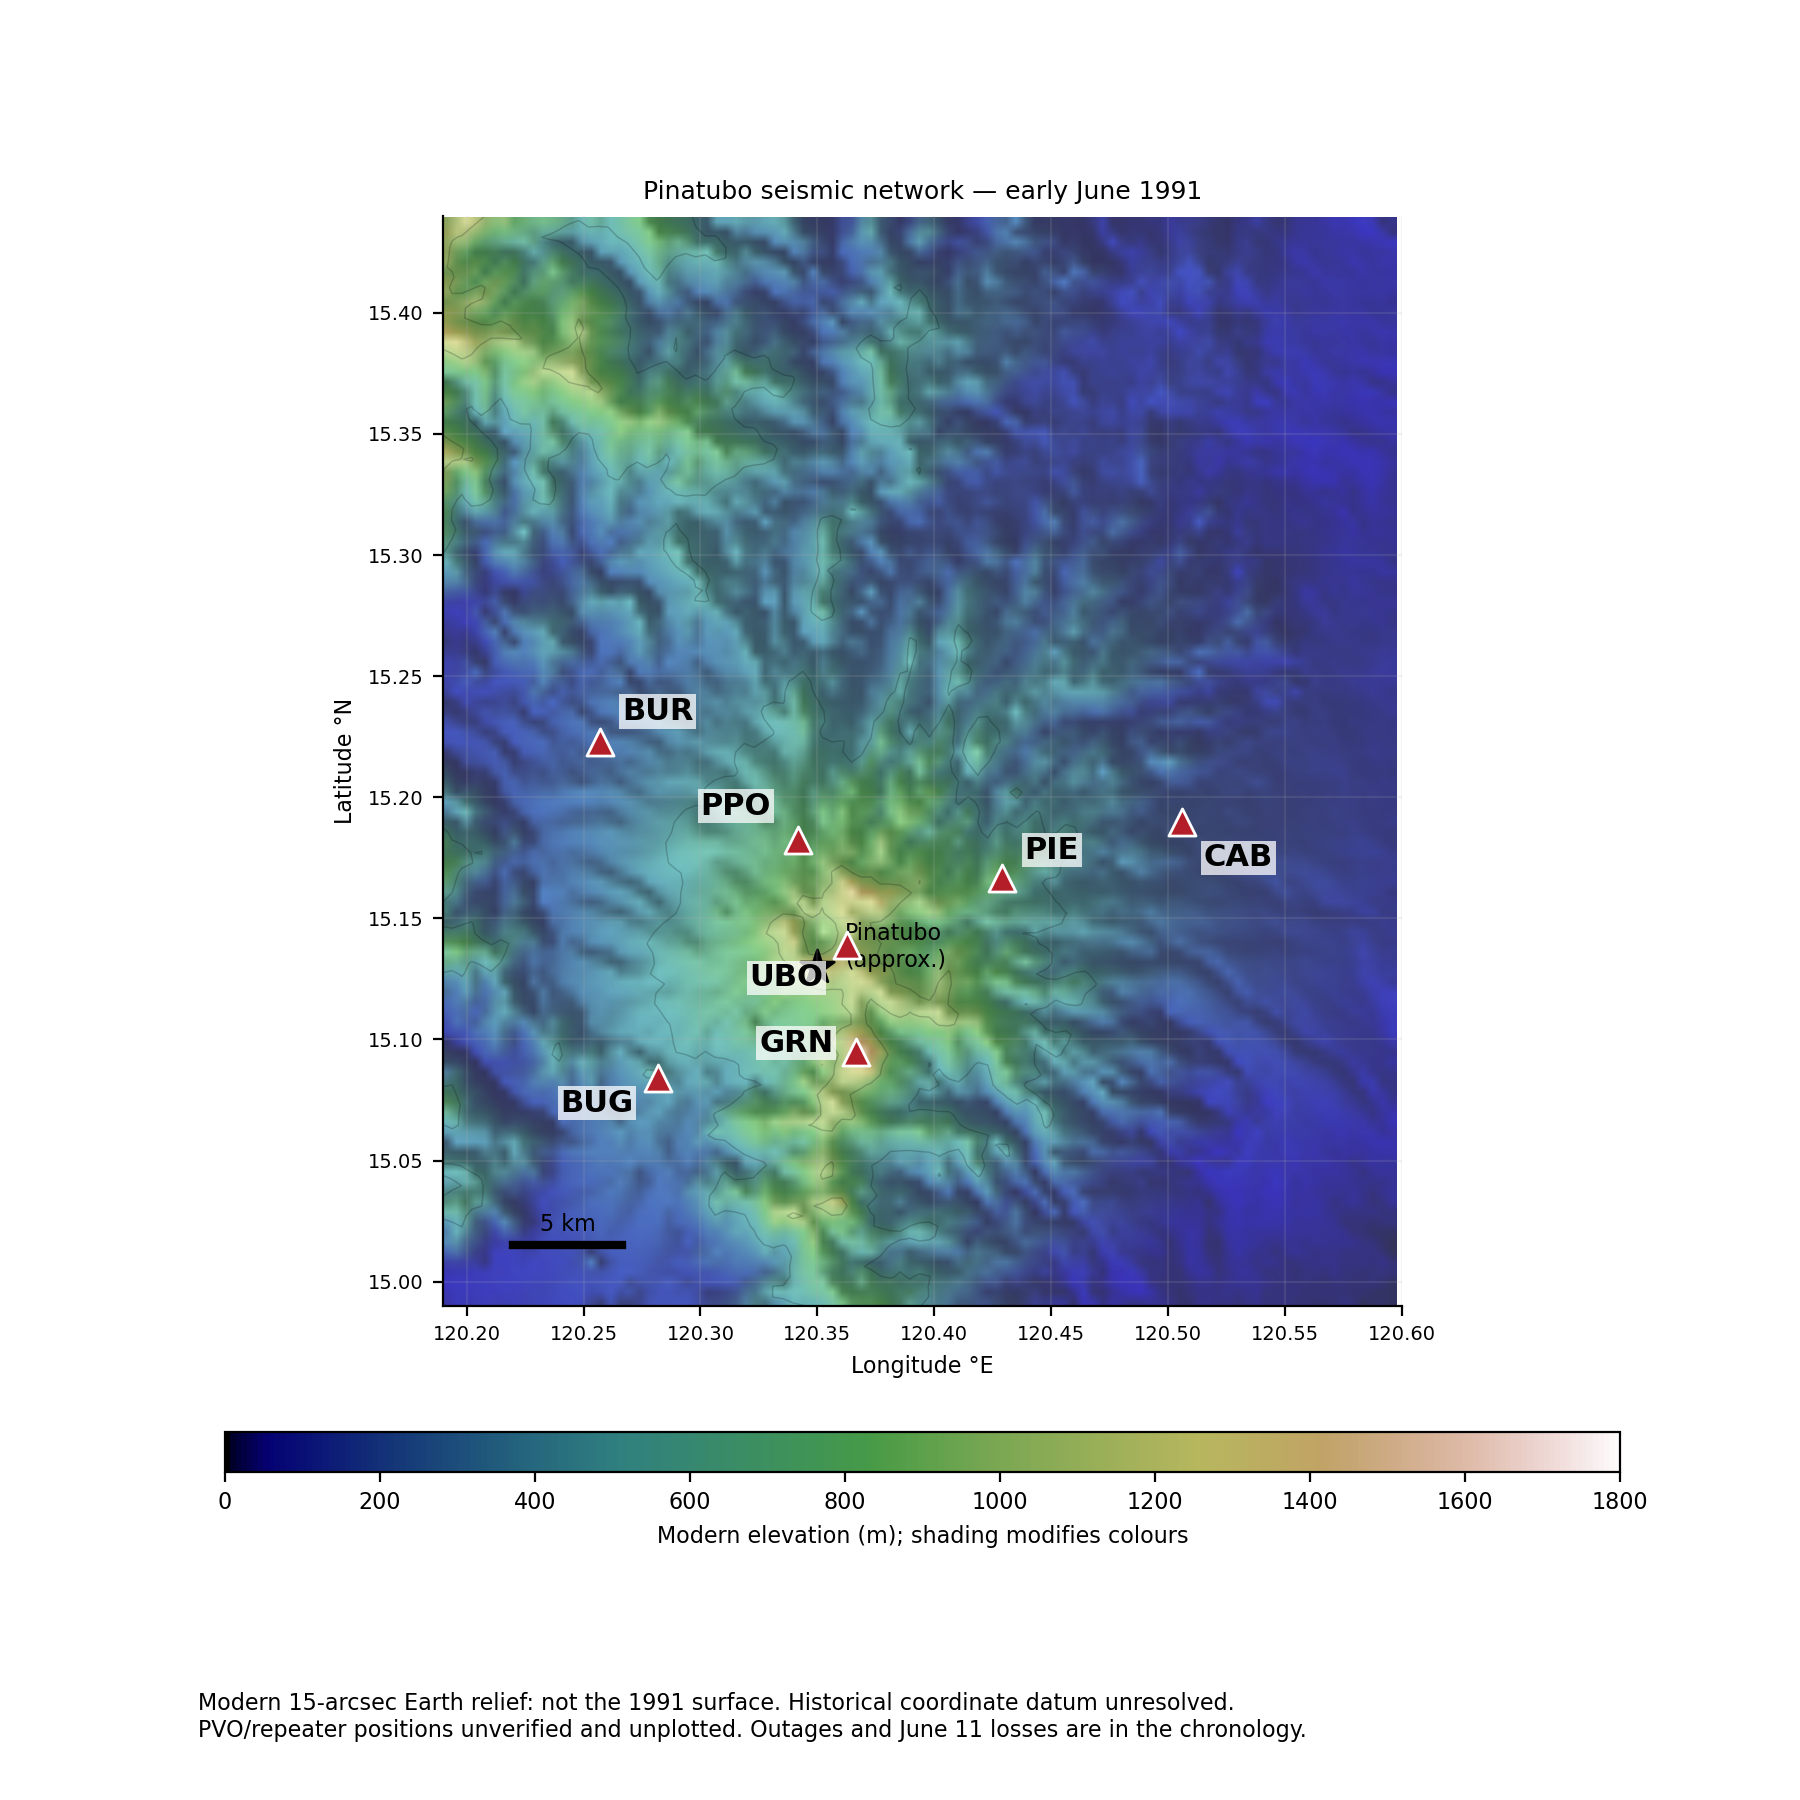

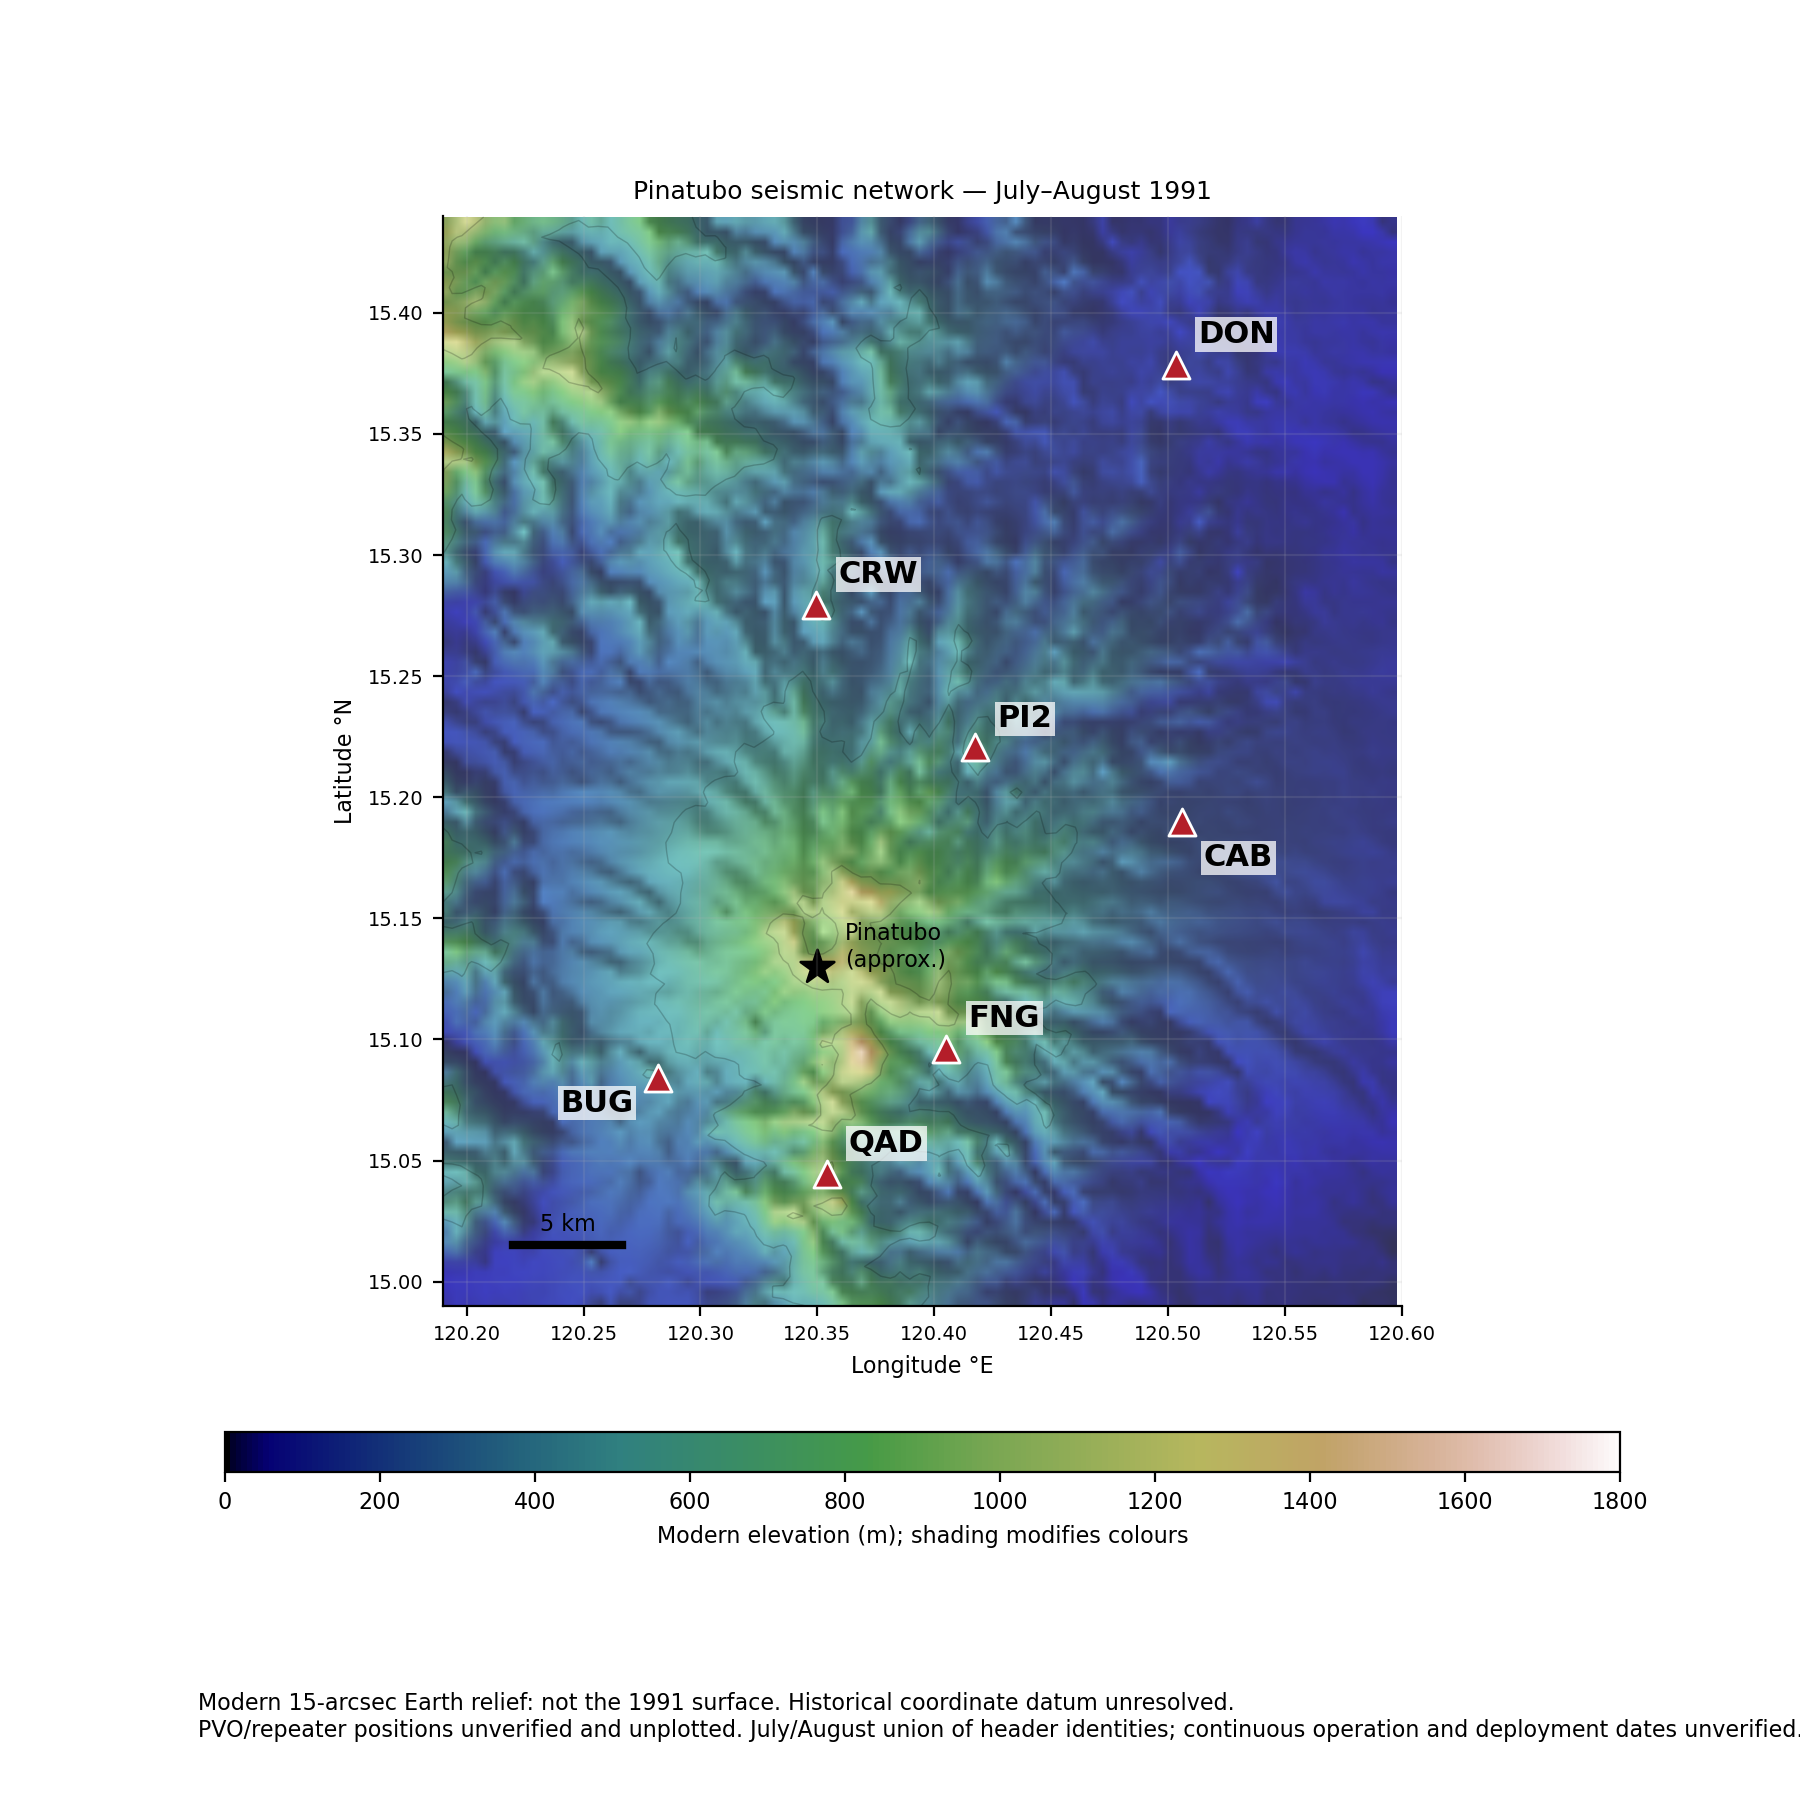

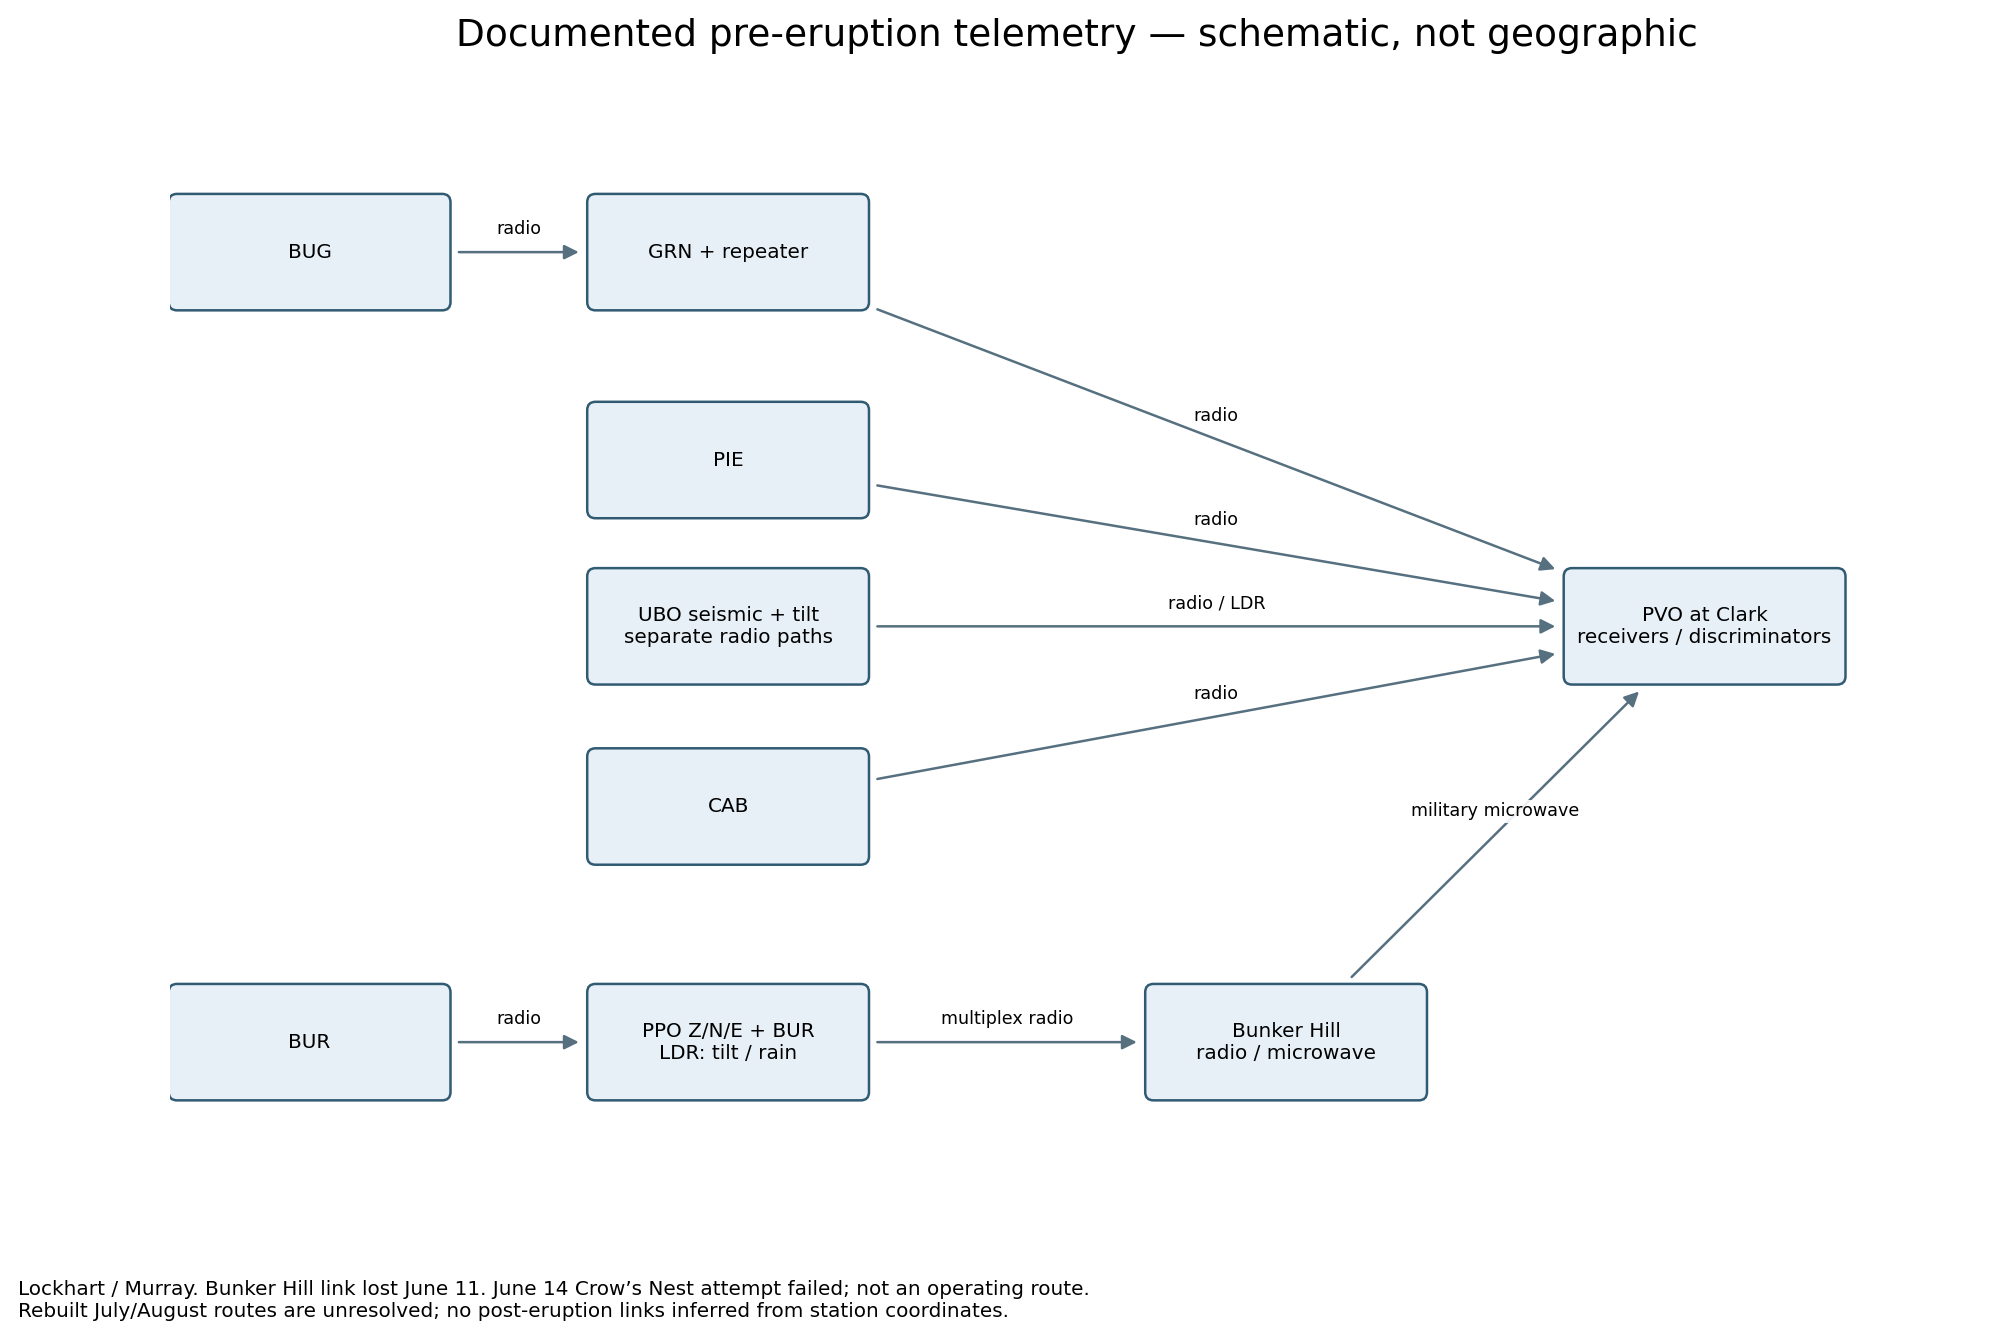

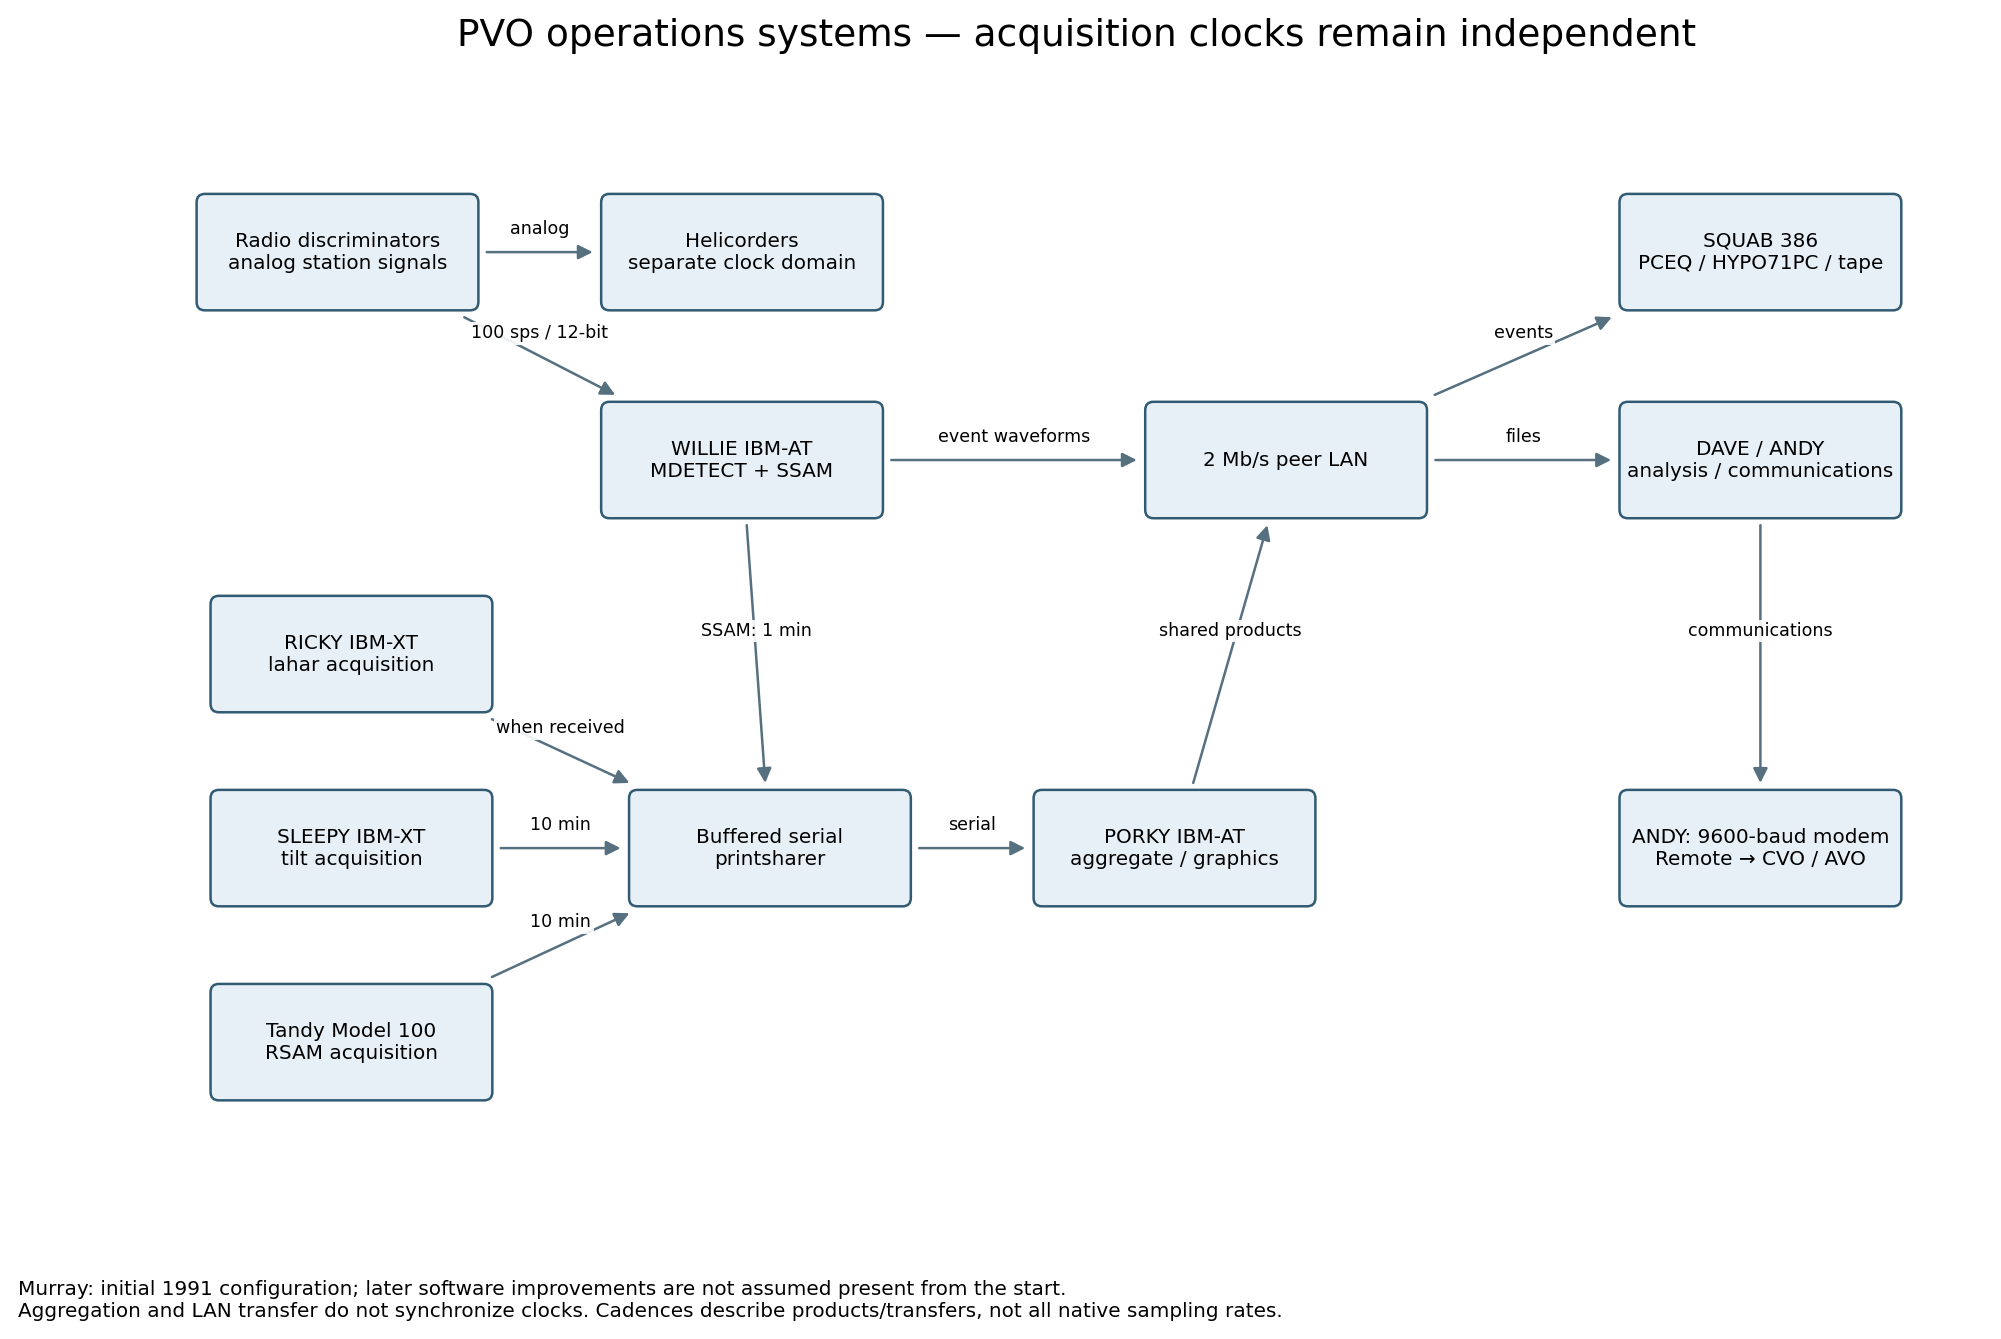

In [3]:
for name in ['network_early_june', 'network_july_august', 'telemetry', 'pvo_operations']:
    display(Image(filename=str(NETWORK / f'{name}.png')))


In [4]:
display(Markdown((NETWORK / 'chronology.md').read_text()))
display(Markdown((NETWORK / 'timing_issues.md').read_text()))


# Pinatubo network chronology — evidence draft

Every change currently documented in the reviewed sources is retained below. Absence of an entry is not evidence of no change. Date precision and source clock basis must be preserved; coordinate discrepancies do not establish relocations.



- **1991-04 (response deployment) — PVO: system installed**. Murray: response equipment taken from USA to Maryland Street apartment at Clark; exact date not stated. Precision: approximate. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **early April 1991 — PHIVOLCS: portable monitoring established**. After April 2 unrest, PHIVOLCS established an observatory west of the volcano and deployed several portable, nontelemetered recorders. Site identities/coordinates/epochs not recovered here. Precision: approximate interval. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-04-05 — VDAP: response team alerted**. VDAP alerted; this is an organizational milestone, not a sensor installation. Precision: day. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-04-23 — VDAP: team deployment**. Three-person USGS team flew to the Philippines with prepared analog telemetry and tilt equipment. Precision: day. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-04-25 — LIL: installed**. L-4 interpretation of printed L-c4; 30 dB attenuation; sensor buried 1 m; 15°11.62 N, 120°31.81 E Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-04-30 — PIE: installed**. L-4; 18 dB attenuation; sensor buried 1 m. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-01 — LIL: removed**. Original Lily Hill installation; retain a distinct station identity from CAB. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-01 — UBO: installed**. L-4; 36 dB attenuation; sensor in rocky fill. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-01 — CAB: installed**. L-4, distinct site from LIL; old coordinates 15°10.76 N, 120°30.61 E are explicitly printed in Appendix 1. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-03 — PPO: installed**. Single vertical L-4 on hut floor; 36 dB attenuation. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **after 1991-05-03 (exact date unknown) — PPO: BUR repeater added**. PPO augmented from single seismic site to receive BUR; documented receiving at Clark by May 7. Exact field addition date not given. Precision: unknown. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-05-05 — BUR: installed**. L-4; 24 dB attenuation; sensor buried 1 m. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-05 12:45 — CAB: attenuation changed**. Reduced from 30 to 24 dB. Precision: minute. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-06 — PPO: first received at Clark**. Separate installation from successful receipt. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-07 — BUR: first received at Clark**. Separate installation from successful receipt. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-11 — BUG: installed**. L-4; 18 dB attenuation; sensor buried 1 m. Appendix latitude 15°05.05 N differs from 15°05.04 in the other coordinate sources. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-12 — PPO: sensor replacement and new components**. Three-component L-22D, 2 Hz: Z attenuation 24 dB; N and E attenuation 30 dB. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-14 — BUG: first repeated to base**. Through GRN. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-14 — GRN: installed**. L-4. 24 dB attenuation is a retrospective inference from calibration signals, not a recorded field setting. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-14 — NETWORK: initial network installed**. Lockhart describes installation during April 25–May 14: seven stations, three repeaters, nine seismic components. First reception and later configuration dates remain separate. Precision: day. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-05-16 — GRN: VO-COM repeater installed**. Telemetry configuration history. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **latter May and early June 1991 — CAB: battery outage**. Approximate interval only; do not invent exact gap start. Precision: approximate interval. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-24 — BUG: lightning damage found**. Visit found destroyed radio and damaged VCO; actual failure time not established. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **about 1991-05-25 — WILLIE: candidate timing/software transition**. Power email Oct 29 2026 recalls GMT/version change around May 25; not a verified correction boundary. Precision: approximate recollection. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **1991-05-28 — BUG: reinstalled**. 18 dB attenuation; confirm instrument serials/response if available. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-30 — PPO: vertical attenuation changed**. PPOZ to 30 dB; no explicit change of N/E settings is stated. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-31 — UBO: tiltmeter site visit**. Companion Ewert chapter independently reports first tilt data on May 31. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-05-31 — UBO: tilt data begin**. Ewert reports UBO tilt data starting May 31, through June 13. This product history differs from June 11 seismic telemetry failure. Precision: day. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **early June 1991 — GRN: sensor reburied**. Depth changed to 1.5 m; date is approximate, no exact epoch boundary is established. Precision: approximate interval. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-02 — PPO: tilt installed on hut floor**. Lockhart PPO Telemetry section; installation/wiring unsuitable, data never reliable. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-10 — PPO: attempted tilt reinstallation**. Lockhart PPO Telemetry section; work cut short, not evidence of successful new installation. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-10 — BUNKER_HILL: guards evacuated**. Guards evacuated, generators subsequently stolen; telephone telemetry loss dated June 11 separately. Precision: day. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-06-11 22:00 — UBO: seismic telemetry lost**. Do not equate this to loss of all tilt data or physical destruction. Precision: minute. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-11 — BUR: Bunker Hill link lost**. Shared loss with PPO channels and LDR path; not necessarily sensor failure. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-11 — PPO: Bunker Hill link lost**. Affected seismic components, tilt and rain-gauge telemetry. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-11 — CAB: back online**. Battery change; reduced water-pump noise after evacuation. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-12 03:41 — UBO: nearby explosion reference**. Explosion time is from PIEZ, not a functioning UBO seismic record; weak transmitter noted during 0600 flyby. Precision: minute. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-13 — UBO: last reported tilt data**. Ewert tilt record ends June 13; exact failure time and timestamp reliability remain unresolved. Precision: day. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-06-14 — CROWS_NEST: replacement repeater attempt failed**. Attempted 5-W UHF/yagi link to receiver 60 feet up Clark mast; no usable reception because path not line-of-sight. Does not establish an operational CRW seismic station at this date. Precision: last attempt bound. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **1991-06-15 — PIE: destroyed**. Do not assume exact midnight shutdown. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-15 — BUG: transmissions lost**. Exposed components damaged by heat; not total destruction of buried equipment. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **1991-06-15 — GRN: destroyed/buried**. Appendix says annihilated; main text says destroyed or buried. Precision: day. Source: Lockhart et al., Appendix 1 unless noted.

- **before 1991-06-15 — PVO: observatory move**. Maryland Street apartment to Dau Complex as unrest intensified; exact date unresolved. Precision: approximate. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **just after 1991-06-15 — PVO: observatory move**. Dau Complex to Clark BaseOps; exact date unresolved. Precision: approximate. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **after 1991-06-15 — NETWORK: reconstruction and new repeater sites**. Second network installed, some sites reoccupied and newly accessible repeater sites used. Exact site-specific dates/routes unresolved. Precision: approximate interval. Source: Ewert for tilt record; Lockhart introduction, network configuration and repeater sections otherwise.

- **by 1991-06-29 — NETWORK: network restoration**. Bautista chapter reports telemetry network restored by June 29; exact site-specific redeployment dates unresolved. Precision: upper bound. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **early July 1991 — PVO: disk replacement**. Murray reports erratic hard disk, replaced with a disk bought in Manila; machine/date not specified. Precision: approximate. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **1991-11 — PVO: observatory move**. System moved off Clark to Quezon City; exact day unresolved. Precision: month. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.

- **date not established — PPO: rain gauge added**. Lockhart PPO telemetry: rain gauge added to LDR platform; precise start and calibration unknown. Precision: unknown. Source: Murray et al. hardware/conclusions; Lockhart; Bautista; supplied Power email as identified in detail.



## Archive observations

July/August headers contain BUG, CAB, CRW, DON, FNG, PI2 and QAD; CAB includes N and Z. These establish recorded identities, not installation dates or valid signals. Old BUR/GRN/PIE/PPO/UBO names persist in some late-June headers after documented failures. Stale configuration, placeholders and timing errors remain hypotheses requiring waveform inspection. PI2L may have been collapsed into EHZ by the previous converter.



Rain/lahar acquisition and remote platform coordinates, calibration and installation dates remain incomplete. BOB/STATIONS.TXT distinguishes LSAC, USAC, MARL and ABAC; these are not invented as georeferenced stations.



Primary references: [Lockhart](https://pubs.usgs.gov/pinatubo/lock/), [Murray](https://pubs.usgs.gov/pinatubo/murray/), [Ewert](https://pubs.usgs.gov/pinatubo/ewert/), [Bautista](https://pubs.usgs.gov/pinatubo/bbautist/). Source files and hashes: ../data/sources.json.

# Timing evidence and correction limits

No universal clock correction is applied. Daily WWV checks were intended, but checks were sporadic; nominal ±0.1 s setting accuracy is not an archive accuracy claim.

## Analog drums / helicorders

**Machine:** Four drum recorders described by Lockhart; individual clock hardware unresolved

**Products:** Paper seismic records

**Clock reference:** Manually synchronized to WWV

**Documented issues:** Daily checks intended but often omitted; manual setting no better than ±0.1 s. Drift/reset history of each drum not quantified. A GOES satellite clock was available but its satellite signal was not receivable there, so it was not used.

**Software offset:** No MDETECT offset applies to drums

**Source:** Lockhart Observatory Timing and Equipment

**Uncertainty:** Do not assume continuous ±0.1 s accuracy; inspect paper time marks and corrections.

## MDETECT

**Machine:** WILLIE (IBM-AT)

**Products:** Triggered digitized seismic events

**Clock reference:** WILLIE PC, manually set to WWV; initially local time

**Documented issues:** PC drift reached minutes on occasions; Power recalls daily/configuration reboots and version/GMT change about May 25.

**Software offset:** Murray: event time tag = PC clock + 8 hours before fix; correction date not established.

**Source:** Murray local/GMT section; Lockhart; Power email Oct 29 2026

**Uncertainty:** Never apply a blanket correction. Conditional local-PC-plus-8 tags could be UTC+16; validate original fields, software versions and epochs.

## SSAM

**Machine:** WILLIE (same PC as MDETECT)

**Products:** 1-minute spectra; later 10-minute BOB summaries

**Clock reference:** Same hardware clock as event acquisition, different early tagging path

**Documented issues:** Software tagged SSAM directly with PC clock; not with the event +8-hour adjustment. Spectral averaging time convention needs confirmation.

**Software offset:** SSAM = PC clock before fix; early SSAM/event tags differ by +8 h for event tags.

**Source:** Murray SSAM and local/GMT sections

**Uncertainty:** Shared clock is not shared timestamp semantics. SSAM_VU/SCANSSAM and XDETECT discussed as later improvements, not proven 1991 deployment versions.

## RSAM / RSAM EVNT

**Machine:** Tandy Model 100

**Products:** Amplitude means and single-channel trigger counts

**Clock reference:** Independent acquisition clock, WWV manual setting reported

**Documented issues:** Clock sometimes drifted by minutes. Transfer to PORKY every 10 minutes is not proof of synchronization.

**Software offset:** No evidence MDETECT +8-hour bug directly applies

**Source:** Murray hardware; Lockhart timing; user-confirmed RSAM trigger interpretation

**Uncertainty:** Check native annual-file padding, missing sentinel and interval start/end semantics separately from actual clock corrections.

## TILT / LDR

**Machine:** SLEEPY (IBM-XT)

**Products:** UBO/PPO tilt, temperature and battery voltage

**Clock reference:** Separate acquisition computer; exact time-tag authority PC vs remote platform unresolved

**Documented issues:** Initial all-clock local-time statement in Murray; precise synchronization practice and later changes for SLEEPY not established.

**Software offset:** No documented MDETECT offset inheritance

**Source:** Murray tilt/hardware; Ewert; Lockhart

**Uncertainty:** Ten-minute logging/transfer does not establish precise timing or alignment with RSAM.

## Lahar / AFM

**Machine:** RICKY (IBM-XT)

**Products:** Lahar detector measurements

**Clock reference:** Separate computer; exact remote/receiver timestamp ownership unresolved

**Documented issues:** Initially standalone; later serial transfer to PORKY via printer port converter and print sharer.

**Software offset:** No documented MDETECT offset inheritance

**Source:** Murray lahar section; BOB STATIONS.TXT names LSAC/USAC/MARL/ABAC

**Uncertainty:** Event-driven transfer cadence; no subsecond clock accuracy claim supported.

## Aggregation / BOB

**Machine:** PORKY (IBM-AT)

**Products:** Copied/converted SSAM, RSAM, tilt and lahar time series

**Clock reference:** Collection/analysis PC, not automatically the source clock

**Documented issues:** Print-sharer buffering and conversion can separate receipt time from measurement time.

**Software offset:** Timestamp copying/conversion details must be checked by product

**Source:** Murray hardware

**Uncertainty:** Do not retime source measurements to PORKY receipt time.

## Picking / hypocenter processing

**Machine:** SQUAB (386)

**Products:** PCEQ phase picks; HYPO71PC origins; tape archive

**Clock reference:** Acquisition timestamps plus analyst processing conventions

**Documented issues:** Processing time is not event time. Catalog local/GMT conventions and any analyst corrections require independent provenance checks.

**Software offset:** Do not infer universal transition from one catalog annotation

**Source:** Murray hardware; catalog time conventions unresolved in this reconstruction

**Uncertainty:** Preserve recorded, interpreted and corrected times separately.

## Analysis / remote access

**Machine:** DAVE and ANDY (IBM-AT)

**Products:** BOB plots, communications, advisories; ANDY 9600-baud modem

**Clock reference:** Analysis computer clocks, not independent physical event references

**Documented issues:** File creation/receipt/plot clocks must not be confused with acquisition clocks.

**Software offset:** Unknown/not established

**Source:** Murray hardware

**Uncertainty:** Record product lineage; network file sharing did not imply clock synchronization.

## Independent references

**Machine:** Local paper records and Manila-held national-network helicorders

**Products:** Potential timing tie points for shared events

**Clock reference:** Must establish station identity and time-mark/clock reliability

**Documented issues:** Manila is about 100 km from Pinatubo, but sensor can be remote from headquarters; account for travel-time differences.

**Software offset:** Use independently validated tie points to estimate offset/drift/reset epochs

**Source:** User-supplied email context; USGS geographical descriptions

**Uncertainty:** Two unchecked clocks establish relative disagreement, not absolute UTC accuracy.

## Response-model audit

Review stage units and nominal sensitivities before doing any response correction. Unknown electronics remain explicit. These models do not justify physical cross-station amplitude comparisons. Matching a recorded timestamp to an approximate gain epoch is also provisional when clocks are uncertain.

In [5]:
from obspy import read_inventory
nominal = read_inventory(str(NETWORK / 'pinatubo_nominal_voltage_models.xml'))
rows = []
for network in nominal:
    for station in network:
        for channel in station:
            response = channel.response
            if response is None:
                continue
            for stage in response.response_stages:
                rows.append(dict(station=station.code, channel=channel.code,
                    epoch_start=str(channel.start_date), stage=stage.stage_sequence_number,
                    input_units=stage.input_units, output_units=stage.output_units,
                    stage_gain=stage.stage_gain, gain_frequency_hz=stage.stage_gain_frequency,
                    status='NOMINAL_MODEL; UNKNOWN_ELECTRONICS'))
display(pd.DataFrame(rows))
print('Analysis metrics retain counts; no response removal is performed.')


,station,channel,epoch_start,stage,input_units,output_units,stage_gain,gain_frequency_hz,status
0,CAB,EHZ,1991-05-01T00:00:00.000000Z,1,M/S,V,170.853570,5.0,NOMINAL_MODEL; UNKNOWN_ELECTRONICS
1,CAB,EHZ,1991-05-01T00:00:00.000000Z,2,V,V,0.031623,5.0,NOMINAL_MODEL; UNKNOWN_ELECTRONICS
2,CAB,EHZ,1991-05-05T04:45:00.000000Z,1,M/S,V,170.853570,5.0,NOMINAL_MODEL; UNKNOWN_ELECTRONICS
3,CAB,EHZ,1991-05-05T04:45:00.000000Z,2,V,V,0.063096,5.0,NOMINAL_MODEL; UNKNOWN_ELECTRONICS
4,PIE,EHZ,1991-04-30T00:00:00.000000Z,1,M/S,V,170.853570,5.0,NOMINAL_MODEL; UNKNOWN_ELECTRONICS
5,PIE,EHZ,1991-04-30T00:00:00.000000Z,2,V,V,0.125893,5.0,NOMINAL_MODEL; UNKNOWN_ELECTRONICS
6,UBO,EHZ,1991-05-01T00:00:00.000000Z,1,M/S,V,170.853570,5.0,NOMINAL_MODEL; UNKNOWN_ELECTRONICS
7,UBO,EHZ,1991-05-01T00:00:00.000000Z,2,V,V,0.015849,5.0,NOMINAL_MODEL; UNKNOWN_ELECTRONICS
8,PPO,EHZ,1991-05-03T00:00:00.000000Z,1,M/S,V,170.853570,5.0,NOMINAL_MODEL; UNKNOWN_ELECTRONICS
9,PPO,EHZ,1991-05-03T00:00:00.000000Z,2,V,V,0.015849,5.0,NOMINAL_MODEL; UNKNOWN_ELECTRONICS


Analysis metrics retain counts; no response removal is performed.


Review the source JSON/evidence under `10_conversion/network_history/data` when metadata need changing; rerun this notebook afterwards. Network source hashes are saved with these products. Continue to notebook **20**.